Trabalho Info 3 - Python Científico - 20/12/2025

Pedro Luna e Enzo Endo

O objetivo desse trabalho é utilizar ferramentas desenvolvidas durantes os trabalhos práticos para realizar um projeto maior se um roteiro pré definido. Ficamos com o tema de modelagem de propagação de virus/doenças.

O nosso trabalho realiza a modelagem da propagação do vírus do covid-19 na frança a partir de dados reais (Johns Hopkins University) de casos acumulados. A modelagem vai ser feita utilizando o modelo SIR (Sucetível-Infectado-Removido/Recuperado) discreto em 3 variações.

Vamos utilizar a abordagem de Allen (1994) para modelar a epidemia em tempo discreto. Esse método substitui o cálculo contínuo com equações diferenciais por intervalos discretos. Pro nosso caso consideramos melhor, pois a implementação é mais intuitiva e podemos simular as mudanças nos grupos (Suscetíveis, Infectados, Recuperados) de forma sequencial.

Vão ser desenvolvidas 3 variações:

1. SIR clássico - Modelagem do artigo de Allen (1994)
2. SIRSD -  Considerando possível reinfecção e diferenciando recuperados de mortos (no lugar de apenas "removidos")
3. SIRSD - Taxas de infecção que mudam com o tempo

Será comparado e apresentado os resultados dos modelos com a evolução real dos casos, realizando também estimativas e aproximações baseadas no que conhecemos sobre a doeça e fontes como o Institut National de la Statistique et des Études Économiques (INSEE, 2021).
https://www.insee.fr/fr/statistiques/5432509?sommaire=5435421

1: Importação das bibliotecas

Numpy: Utilizada para manipular arrays onde vão estar os os diferentes grupos além de algumas funções específicas

Pandas: Utilizada principalmente para manipular e organizar os dados que vamos utlizar para a análise do avanço da pandemia

Matplotlib: Utilizada para Visualizar as principais informações estudadas nos dados reais e modelos refinados 

Scipy: Utilizada para encontrar os melhores parâmetros possiveis para otimizar o modelo  

In [195]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

2: Origem dos Dados

Importamos as séries temporais de casos confirmados acumulados do repositório da Johns Hopkins University, base de dados global utilizada para o monitoramento da pandemia. Os dados são estruturados cronologicamente por país, fornecendo o que precisamos para o ajuste das curvas e a calibração dos parâmetros do modelo.

In [196]:
#data (Johns Hopkins University)
# URL = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
# df = pd.read_csv(URL)

df = pd.read_csv('time_series_covid19_confirmed_global.csv')


3: Preparação dos dados Necessários

Como os dados da França aparecem divididos por territórios, nós somamos todas as regiões para obter um valor único que represente o país inteiro. Dessa forma, utilizamos apenas o nome do país e o total de casos acumulados por dia, ignorando as divisões regionais e as coordenadas geográficas.

Além disso, obtemos o total de dias e fizemos uma estimativa para o tempo de infecção de 10 dias. Não temos os casos diários diretamente, então fizemos a diferença entre "hoje e ontem" e somamos os últimos 8 dias (para obter o total de infectados no instante, com uma soma em uma janela móvel).

In [197]:
# filtrar França - soma dos casos por região e ajustar formato

france_filtered = df[df['Country/Region'] == 'France']
time_series_only = france_filtered.iloc[:, 4:]
france_data = time_series_only.sum(axis=0)
france_data.index = pd.to_datetime(france_data.index, errors='coerce')

y_real_acc = france_data.values.astype(float) # casos totais (C)
x_days = np.arange(len(y_real_acc)) # total de dias

# novos casos (Hoje - Ontem)
y_daily = np.diff(y_real_acc, prepend=0)

# estimativa ativos - Soma dos novos casos dos últimos 10 dias
active_series = pd.Series(y_daily).rolling(window=10).sum()
y_real_active = active_series.fillna(0).values #preenche os primeiros valores com 0 para fazer sentido

N = 67500000 # população aproximada da frança

C:\Users\pedro\AppData\Local\Temp\ipykernel_7472\2216400810.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  france_data.index = pd.to_datetime(france_data.index, errors='coerce')


4: Verificação dos dados

Essa cédula serve apenas para verificar se os dados processados foram os que realmente desejamos. Podemos comparar com o csv original.

In [198]:
print(f"Data: {len(x_days)} days of the pandemic.")
print(f"Final cumulative total: {y_real_acc[-1]:,.0f}")

#dados primeiros dias
print(y_real_acc[20:30])    # casos acumulados
print(y_daily[30:40])       # enovos casos diários
print(y_real_active[40:50]) # estimação infectados

Data: 1143 days of the pandemic.
Final cumulative total: 39,866,718
[11. 11. 11. 11. 12. 12. 12. 12. 12. 12.]
[ 0.  0.  0.  0.  2.  4. 20. 19. 43. 30.]
[ 179.  200.  276.  414.  602.  930. 1087. 1354. 1683. 2163.]


5: Modelagem SIR

Considerando um intervalo de tempo $\Delta t = 1$ dia, as equações que mostram a dinâmica do sistema são:

$$\begin{aligned}
S_{t+1} &= S_t - \frac{\beta}{N} S_t I_t \\
I_{t+1} &= I_t + \frac{\beta}{N} S_t I_t - \gamma I_t \\
R_{t+1} &= R_t + \gamma I_t
\end{aligned}$$

**Variáveis de Estado (População no dia $t$):**

* **$S_t$**: Número de indivíduos suscetíveis.
* **$I_t$**: Número de indivíduos infectados.
* **$R_t$**: Número de indivíduos removidos (imunizados ou mortos).
* **$N$**: População total.

**Parâmetros do Modelo:**

* **$\beta$**: Coeficiente de transmissão (taxa de contato efetiva diária).
* **$\gamma$**: Taxa de recuperação diária (onde $1/\gamma$ representa o período médio de infecção).

In [199]:
def sir_discrete(t, beta, gamma, return_full=False):
    
    #cria arrays para serem preenchidos com a atualização diária do sistema
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    
    I[0] = max(y_real_acc[0], 1) #garente que a pandemia vai começar com pelomenos 1 infectados
    S[0] = N - I[0] 
    
    for i in range(len(t) - 1):
        
        #modelagem apresentada
        new_inf = (beta * S[i] * I[i]) / N #novos infectados no dia
        new_rec = gamma * I[i] #novos recuperados no dia
        
        #atualização das variáveis
        #max (0,_) garante que a gente não chegue em valores negativos
        S[i+1] = max(0, S[i] - new_inf) #próximo dia sucetíveis = sucetiveis atuais - infectados atuais
        I[i+1] = max(0, I[i] + new_inf - new_rec) #próximo dia infectados = infectados atuais - removidos atuais
        R[i+1] = R[i] + new_rec
    
    #dois possiveis returns: um para a otimização e outra para o plot/análise
    if return_full:
        return S, I, R, (I + R) #plot/análise
    return I + R #otimização (soma de arrays de todos os que foram infectados nesse tempo)

6: Modelagem SIRS-D

Considerando a introdução da reinfecção e da letalidade no sistema, as equações  são:

$$\begin{aligned}
S_{t+1} &= S_t - \frac{\beta}{N} S_t I_t + \xi R_t \\
I_{t+1} &= I_t + \frac{\beta}{N} S_t I_t - \gamma I_t - \mu I_t \\
R_{t+1} &= R_t + \gamma I_t - \xi R_t \\
D_{t+1} &= D_t + \mu I_t
\end{aligned}$$

**Variáveis de Estado (População no dia $t$):**

* **$S_t$**: Número de indivíduos suscetíveis.
* **$I_t$**: Número de indivíduos infectados.
* **$R_t$**: Número de indivíduos recuperados (imunizados temporariamente).
* **$D_t$**: Número acumulado de óbitos.
* **$N$**: População total.

**Novos Parâmetros do Modelo:**

* **$\xi$**: Taxa de perda de imunidade (fração de recuperados que voltam a ser suscetíveis por dia).
* **$\mu$**: Taxa de letalidade diária (probabilidade de óbito para um infectado).

In [200]:
def sirsd_discrete(t, beta, gamma, xi, mu, return_full=False):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    D = np.zeros(len(t)) #mortes diárias
    C = np.zeros(len(t)) #infectados diários
    
    I[0] = max(y_real_acc[0], 1)
    C[0] = max(y_real_acc[0], 1)
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):

        #modelagem apresentadas
        new_inf = (beta * S[i] * I[i]) / N #igual a SIR
        new_rec = gamma * I[i] #igual a SIR
        new_death = mu * I[i] #mortes diárias
        new_susc = xi * R[i]  #perda de imunidade
        
        #atualização das diária dos grupos
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec - new_death) 
        R[i+1] = max(0, R[i] + new_rec - new_susc) # recuperados do dia + novos recuperados - novos sucetíveis
        D[i+1] = D[i] + new_death #apenas mortes por dia
        C[i+1] = C[i] + new_inf #contagem total de casos
        
    if return_full:
        return S, I, R, D, C 
    return C




7: Modelagem SIRS-D Dinâmico (Por Fases)

Nesta abordagem, a estrutura dos compartimentos é a mesma do modelo SIRS-D, porém o coeficiente de transmissão ($\beta_t$) varia ao longo do tempo.

O período analisado é dividido em intervalos temporais, definidos pelos pontos de corte ($x_{nodes}$). Dentro de cada intervalo, o valor de $\beta$ permanece constante, se sjustando apenas na transição entre fases:

$$
\beta_t = 
\begin{cases} 
\beta_1 & \text{se } t_{início} \le t < x_1 \\
\beta_2 & \text{se } x_1 \le t < x_2 \\
\vdots & \vdots \\
\beta_k & \text{se } x_{k-1} \le t \le t_{final}
\end{cases}
$$

**Alteração nos Parâmetros:**

* **$\beta_t$** (Beta Variável): Assume valores diferentes para cada fase, conseiderando mudanças no comportamento social, políticas públicas e diferentes variantes da doença.
* **$x_{nodes}$**: Pontos temporais para as as trocas de fase.

**Implementação:** Para este caso, definimos o número de intervalos como **4**. Essa escolha foi baseada na identificação de quatro grandes ondas de contágio no período , conforme referências utilizadas (INSEE, 2021).

In [ ]:
num_intervalos = 4  
x_nodes = np.linspace(0, len(x_days), num_intervalos + 1)

def sirs_dynamic_discrete(t, gamma, xi, mu, *betas_array, return_full=False):
    
    #mesmos parâmetros anteriores
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    D = np.zeros(len(t)) 
    C = np.zeros(len(t))
    
    I[0] = max(y_real_acc[0], 1)
    C[0] = max(y_real_acc[0], 1)
    S[0] = N - I[0]
    
    
    for i in range(len(t) - 1):
        
        idx = np.searchsorted(x_nodes, i, side='right') - 1 #identifica o índice do intervalo  onde o dia 'i' se está
        idx = max(0, min(idx, len(betas_array) - 1)) # garante que o índice esteja dentro dos limites do array
        
        # Seleciona o Beta correto naquele dia
        beta_t = betas_array[idx]
       
        # mesma modelagem do sirsd
        new_inf = (beta_t * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_death = mu * I[i]
        new_susc = xi * R[i]
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec - new_death)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        D[i+1] = D[i] + new_death
        C[i+1] = C[i] + new_inf
        
    if return_full: 
        return S, I, R, D, C 
    return C

Nota sobre criação de funções:  

 Como a modelagem de cada um dos sistemas é incremental, seria possível criar apenas uma função com vários condicionais dentro para cada um dos casos de estudo. Entratanto, essa abordagem não foi escolhida pois iria dificultar a leitura do código e ficaria mais confuso na hora de chamar as funções para a otmização e plotagem. 

8: Restrições

Por se tratar de um modelo real de uma doença conhecida, algumas restrições tem que ser impostas para que o sistema não encontre parâmetros que não refletem a realidade (como um tempo de infecção muito baixo ou uma mortalidade alta demais). Definimos pontos de partida convenientes para acelerar a convergência.


In [ ]:

#Configuração de limites 

MIN_DIAS_RECUPERACAO = 7    
MAX_DIAS_RECUPERACAO = 21  
MIN_DIAS_IMUNIDADE   = 62  
MAX_DIAS_IMUNIDADE   = 365 
MIN_PROB_MORTE_DIA   = 0.00001 
MAX_PROB_MORTE_DIA   = 0.001   
MAX_BETA = 5.0   

gamma_min = 1 / MAX_DIAS_RECUPERACAO #recuperação
gamma_max = 1 / MIN_DIAS_RECUPERACAO

xi_min = 1 / MAX_DIAS_IMUNIDADE #perda de imunidade
xi_max = 1 / MIN_DIAS_IMUNIDADE

print(f"Limites convertidos:") #limites convertidos para os parâmetros
print(f" > Gamma: {gamma_min:.4f} a {gamma_max:.4f}")
print(f" > Xi:    {xi_min:.5f} a {xi_max:.5f}")



Limites convertidos:
 > Gamma: 0.0476 a 0.1429
 > Xi:    0.00274 a 0.01613
------------------------------------------------------------


9: Otimização

Utilizamos algoritmos de minimização para ajustar as curvas teóricas aos dados reais, buscando reduzir o erro  entre a simulação e o histórico. 

 Parâmetros
* **SIR Clássico:** Ajusta $\beta$ e $\gamma$.
* **SIRS-D (Estático):** Ajusta $\beta, \gamma, \xi$ e $\mu$.
* **SIRS-D (Dinâmico):** Ajusta o vetor de **Betas ($\beta_{1} \dots \beta_k$)**, mantendo $\gamma, \xi, \mu$ constantes.

O algoritmo busca encontrar o valor ótimo para os parâmetros que minimiza o erro.

In [ ]:
# otmização

print("Início otimização")

#################################################################################################################

#SIR

#limites impostos SIR
bounds_sir = ([0.0, gamma_min], [MAX_BETA, gamma_max])

#otimização SIR
popt_sir, _ = curve_fit(sir_discrete, x_days, y_real_acc, 
                        p0=[0.1, 0.1], 
                        bounds=bounds_sir)

#################################################################################################################

#SIRSD

#valores iniciais
p0_sirsd = [0.1, 0.1, 0.005, 0.0001] # Parâmetros: Beta, Gamma, Xi, Mu

#limites imporstos SIRSD
bounds_sirsd = ([0.0, gamma_min, xi_min, MIN_PROB_MORTE_DIA], 
                [MAX_BETA, gamma_max, xi_max, MAX_PROB_MORTE_DIA])

#Otimização SIRSD
popt, _ = curve_fit(sirsd_discrete, x_days, y_real_acc, 
                    p0=p0_sirsd, 
                    bounds=bounds_sirsd)

#################################################################################################################

# SIRSD Dinâmico

#valores iniciais
init_dyn = [0.08, 0.005, 0.0005] + [0.15] * num_intervalos # Parâmetros: Gamma, Xi, Mu, [Beta1, Beta2, ... BetaN]

#limites impostos
lower_fixed = [gamma_min, xi_min, MIN_PROB_MORTE_DIA] # parte fixa: [Gamma, Xi, Mu]
upper_fixed = [gamma_max, xi_max, MAX_PROB_MORTE_DIA]
lower_betas = [0.0] * num_intervalos # parte Variável: [Beta, Beta, ...]
upper_betas = [MAX_BETA] * num_intervalos
low_dyn = lower_fixed + lower_betas #concatenação
up_dyn  = upper_fixed + upper_betas

#Otimização SIRSD Dinâmico
popt_dyn, _ = curve_fit(sirs_dynamic_discrete, x_days, y_real_acc, 
                        p0=init_dyn, 
                        bounds=(low_dyn, up_dyn), 
                        maxfev=30000)


print(f"Otimização finalizada")

10: Simulação com Parâmetros Otimizados

Com os melhores parâmetros encontrados pelo algoritmo, executamos a simulação definitiva para gerar os gráficos.

*  O operador * extrai os valores da lista otimizada e os insere  na função como argumentos ($\beta, \gamma, \dots$).  
*  return_full=True Configura o modelo para retornar as séries temporais completas de todos os grupos, permitindo a plotagem e comparação com os dados reais.

In [203]:
S_sir, I_sir, R_sir, C_sir = sir_discrete(x_days, *popt_sir, return_full=True)

S_sirsd, I_sirsd, R_sirsd, D_sirsd, C_sirsd = sirsd_discrete(x_days, *popt, return_full=True)

S_dyn, I_dyn, R_dyn, D_dyn, C_dyn = sirs_dynamic_discrete(x_days, *popt_dyn, return_full=True)

11: Relatório com os resultados

Antes dos gráficos, é gerado um relatório com os principais parâmetros e informações encontradas depois da otimização. Serve para a comparação e avaliação do modelo. Podemos verificar se os resultaods encontrados são realistas.

Além dos parâmetros mais diretos e óbvios apresentados, temos:

**R0**

É a média de novos casos gerados por um único indivíduo infectado em uma população suscetível.

* **$R_0 > 1$**: A epidemia cresce.
* **$R_0 < 1$**: A epidemia diminui.

**Letalidade**

Representa a porcentagem de indivíduos infectados que evoluem para a morte. É o indicador que mede a gravidade da doença entre os doentes.

* **Cálculo no modelo**: É a proporção da taxa de mortalidade ($\mu$) em relação à saída total do estado doente (recuperação + morte).

In [ ]:

print(f"{'Comparação modelos':^80}")


# [1] MODELO SIR

beta, gamma = popt_sir
print(f"\n[1] MODELO SIR (Básico)")
print(f"    ├─ Beta: {beta:.4f}  |  Gamma: {gamma:.4f}")
print(f"    └─ R0:   {beta/gamma:.4f}   (Imunidade Permanente)")

# [2] MODELO SIRS-D (ESTÁTICO - MÉDIA GERAL)

beta, gamma, xi, mu = popt

recuperacao_dias = 1 / gamma 
imunidade_dias = 1 / xi 
letalidade_pct = (mu / (gamma + mu)) * 100
r0 = beta / (gamma + mu)

print(f"\n[2] MODELO SIRS-D (Estático)")
print(f"    ├─ Beta: {beta:.4f}  |  Gamma: {gamma:.4f} (~{recuperacao_dias:.1f} dias) |  Mu: {mu:.5f}")
print(f"    ├─ Xi:   {xi:.5f} ({imunidade_dias:.1f} dias de imunidade)")
print(f"    └─ R0:   {r0:.4f}   |  Letalidade: {letalidade_pct:.2f}%")


# [3] SIRSD Dinâmico

# Separa os parâmetros: Gamma, Xi, Mu e a lista de Betas
gamma, xi, mu, *betas = popt_dyn 

# Cálculos Fixos
imunidade_dias = 1 / xi 
letalidade_pct = (mu / (gamma + mu)) * 100

print(f"\n[3] MODELO DINÂMICO (Por Fases)")
print(f"    [PARÂMETROS BIOLÓGICOS FIXOS]")
print(f"    ├─ Gamma: {gamma:.4f} (Recuperação ~{1/gamma:.1f} dias)")
print(f"    ├─ Mu:    {mu:.5f}")
print(f"    ├─ Xi:    {xi:.5f} ({imunidade_dias:.1f} dias de imunidade)")
print(f"    └─ Letalidade do Modelo: {letalidade_pct:.2f}%")

print(f"\n    [FASES DE TRANSMISSÃO (BETA VARIÁVEL)]")

# loop que mostra os valores de beta de acordo com o intervalo de tempo
for i, b in enumerate(betas):

    if i < len(x_nodes) - 1:
        #o início é o nó atual e o fim é o próximo nó
        start_day = int(x_nodes[i])
        end_day   = int(x_nodes[i+1])
        
        r0 = b / (gamma + mu)
        
        print(f"    ├─ Fase {i+1:02d} (Dia {start_day:4d} a {end_day:4d}): "
              f"Beta = {b:.4f}  ->  R0 ≈ {r0:.2f}")



                               Comparação modelos                               

[1] MODELO SIR (Básico)
    ├─ Beta: 0.0722  |  Gamma: 0.0501
    └─ R0:   1.4424   (Imunidade Permanente)

[2] MODELO SIRS-D (Estático)
    ├─ Beta: 0.1199  |  Gamma: 0.0967 (~10.3 dias) |  Mu: 0.00100
    ├─ Xi:   0.00495 (202.1 dias de imunidade)
    └─ R0:   1.2263   |  Letalidade: 1.02%

[3] MODELO DINÂMICO (Por Fases)
    [PARÂMETROS BIOLÓGICOS FIXOS]
    ├─ Gamma: 0.1340 (Recuperação ~7.5 dias)
    ├─ Mu:    0.00100
    ├─ Xi:    0.00274 (365.0 dias de imunidade)
    └─ Letalidade do Modelo: 0.74%

    [FASES DE TRANSMISSÃO (BETA VARIÁVEL)]
    ├─ Fase 01 (Dia    0 a  285): Beta = 0.1801  ->  R0 ≈ 1.33
    ├─ Fase 02 (Dia  285 a  571): Beta = 0.1340  ->  R0 ≈ 0.99
    ├─ Fase 03 (Dia  571 a  857): Beta = 0.1708  ->  R0 ≈ 1.27
    ├─ Fase 04 (Dia  857 a 1143): Beta = 0.1858  ->  R0 ≈ 1.38


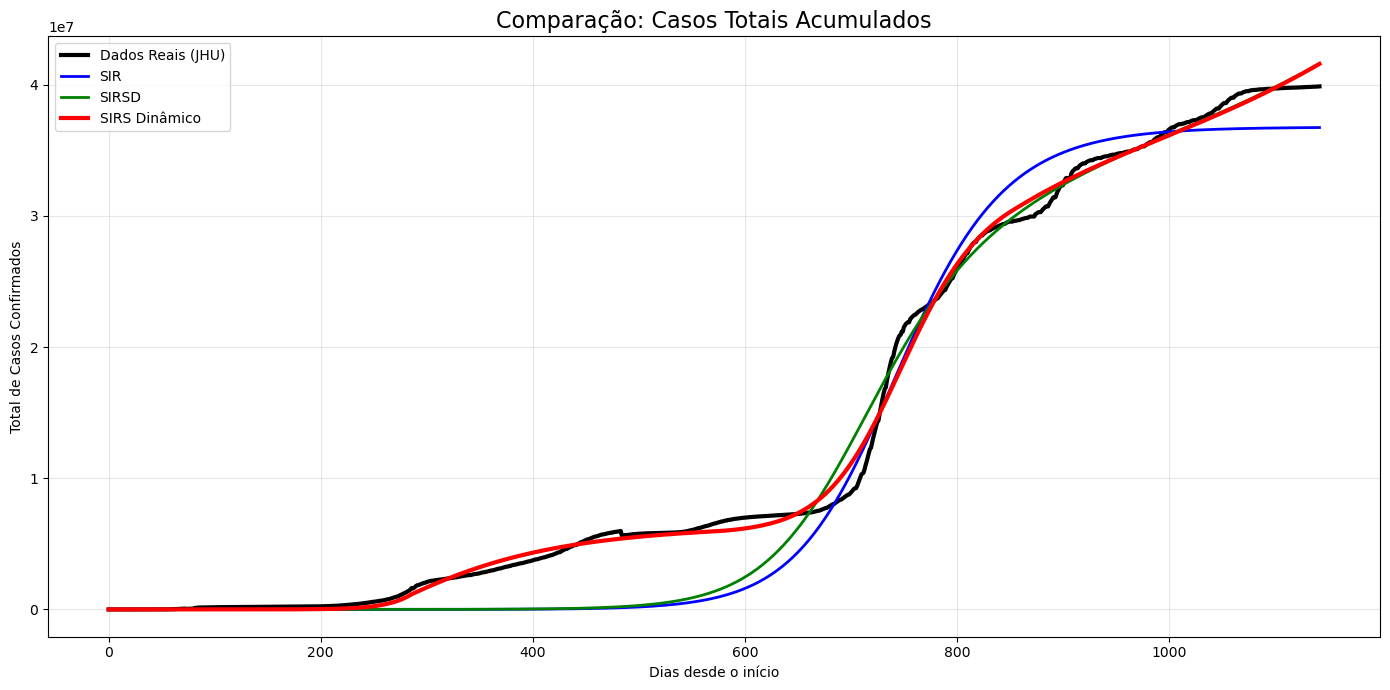

In [205]:
plt.figure(figsize=(14, 7))
plt.title("Comparação: Casos Totais Acumulados", fontsize=16)

# Dados reais
plt.plot(x_days, y_real_acc, color='black', label='Dados Reais (JHU)', alpha=1, linewidth=3)

# Modelos
plt.plot(x_days, C_sir, label='SIR', linestyle='-', color='blue', linewidth=2)
plt.plot(x_days, C_sirsd, label='SIRSD', linestyle='-', color='green', linewidth=2)
plt.plot(x_days, C_dyn, label='SIRS Dinâmico', color='red', linewidth=3)

plt.ylabel("Total de Casos Confirmados")
plt.xlabel("Dias desde o início")
plt.legend()
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

plt.tight_layout()
plt.show()

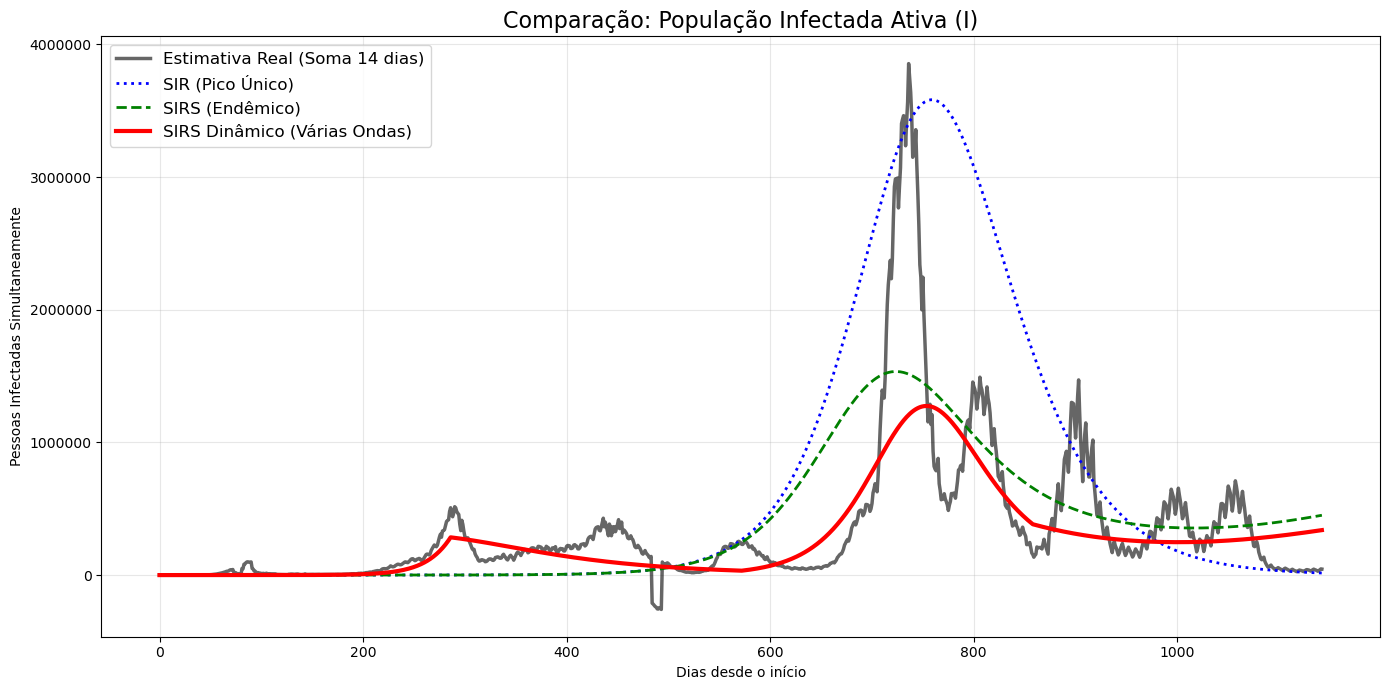

In [206]:

plt.figure(figsize=(14, 7))
plt.title("Comparação: População Infectada Ativa (I)", fontsize=16)



plt.plot(x_days, y_real_active, color='black', alpha=0.6, label='Estimativa Real (Soma 14 dias)', linewidth=2.5)
# plt.fill_between(x_days, y_real_active, color='black', alpha=0.1)

# 2. OS MODELOS
plt.plot(x_days, I_sir, label='SIR (Pico Único)', linestyle=':', color='blue', linewidth=2)
plt.plot(x_days, I_sirsd, label='SIRS (Endêmico)', linestyle='--', color='green', linewidth=2)
plt.plot(x_days, I_dyn, label='SIRS Dinâmico (Várias Ondas)', color='red', linewidth=3) # Destaque no dinâmico

# Detalhes
plt.ylabel("Pessoas Infectadas Simultaneamente")
plt.xlabel("Dias desde o início")
plt.legend(loc='upper left', fontsize=12)
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style='plain', axis='y') # Remove notação científica (1e6)

plt.tight_layout()
plt.show()

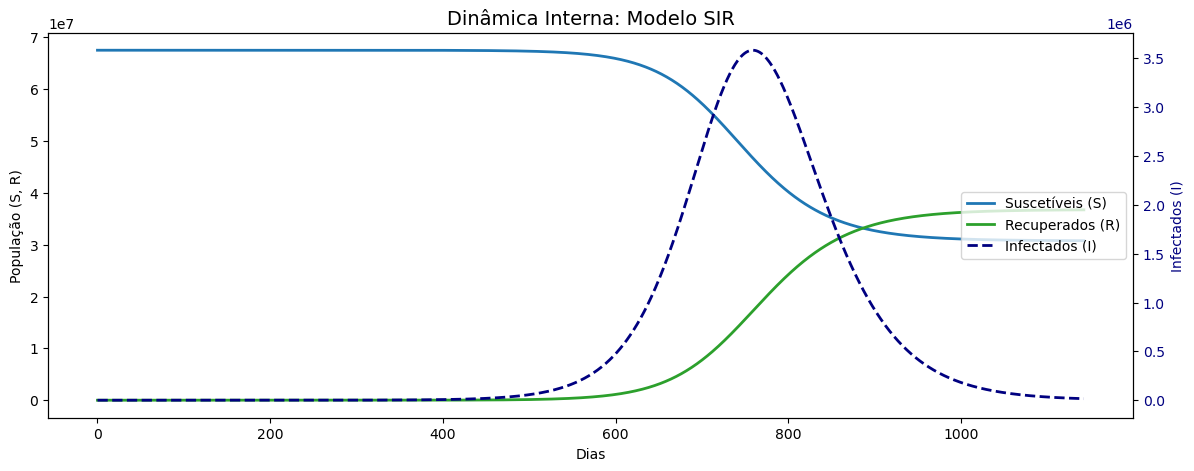

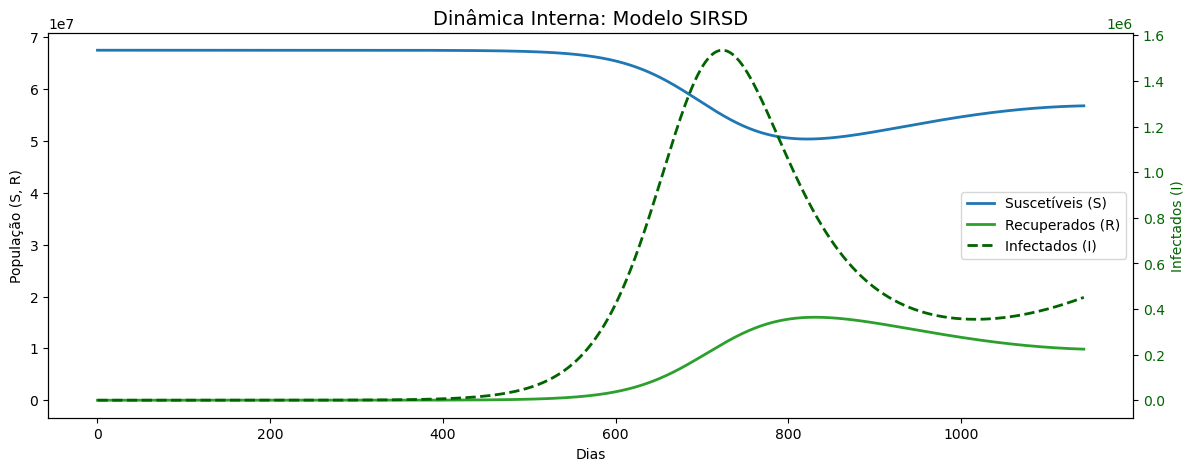

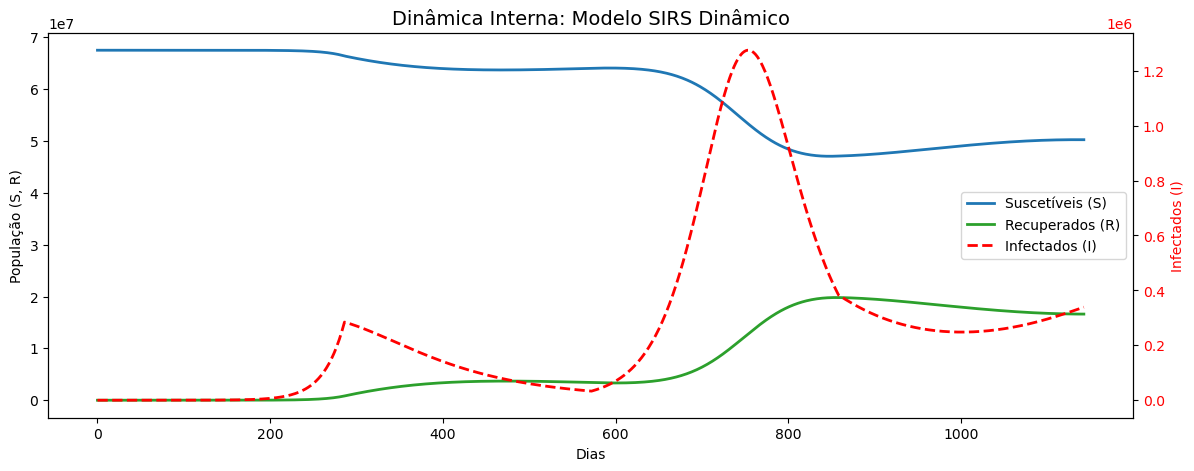

In [207]:
def plot_dynamics(model_name, S, I, R, color_i):
    fig, ax1 = plt.subplots(figsize=(14, 5))
    ax1.set_title(f"Dinâmica Interna: {model_name}", fontsize=14)
    
    # Eixo Esquerdo: S e R
    ax1.set_xlabel("Dias")
    ax1.set_ylabel("População (S, R)", color='black')
    line1, = ax1.plot(x_days, S, label='Suscetíveis (S)', color='tab:blue', linewidth=2)
    line2, = ax1.plot(x_days, R, label='Recuperados (R)', color='tab:green', linewidth=2)
    
    # Eixo Direito: I
    ax2 = ax1.twinx()
    line3, = ax2.plot(x_days, I, label='Infectados (I)', color=color_i, linewidth=2, linestyle='--')
    ax2.set_ylabel("Infectados (I)", color=color_i)
    ax2.tick_params(axis='y', labelcolor=color_i)
    
    # Legenda Unificada
    lines = [line1, line2, line3]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right')
    
    plt.show()

plot_dynamics("Modelo SIR", S_sir, I_sir, R_sir, 'navy')
plot_dynamics("Modelo SIRSD", S_sirsd, I_sirsd, R_sirsd, 'darkgreen')
plot_dynamics("Modelo SIRS Dinâmico", S_dyn, I_dyn, R_dyn, 'red')